# Анализ рынка квартир Алматы

**Данные:** 1 200 объявлений о продаже квартир с сайта [kn.kz](https://www.kn.kz/almaty/prodazha-kvartir/), собраны парсером (снимок рынка, ноябрь 2025).

**Цель:** понять, сколько стоит квартира в Алматы и от чего зависит цена.

**Вопросы:**
1. Сколько стоит квартира в зависимости от количества комнат?
2. Что сильнее всего влияет на цену?
3. Новостройки дороже старых домов?
4. Правда ли, что первый и последний этаж дешевле?
5. Какие квартиры чаще всего продаются?

Бонус: модель, которая оценивает цену квартиры по её параметрам.

## 1. Сбор данных

Парсер проходит по страницам объявлений kn.kz и забирает из каждого объявления: количество комнат, площадь, цену, этаж, год постройки и адрес.

Данные уже собраны и лежат в `data/almaty_housing_raw.csv`, поэтому по умолчанию парсер **не запускается** (`RUN_SCRAPER = False`). Чтобы собрать свежие данные, поставь `True`. Учти, что вёрстка сайта со временем меняется и парсер может потребовать правок.

In [ ]:
import re
import time

import requests
import pandas as pd
from bs4 import BeautifulSoup

RUN_SCRAPER = False   # True — собрать данные заново с сайта
DATA_PATH = 'data/almaty_housing_raw.csv'


def scrape_kn(pages=40):
    url_template = 'https://www.kn.kz/almaty/prodazha-kvartir/?page={}'
    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    data = []

    for page in range(1, pages + 1):
        print(f'Страница {page}...')
        try:
            res = requests.get(url_template.format(page), headers=headers, timeout=10)
        except Exception as e:
            print(f'  не удалось загрузить: {e}')
            continue

        soup = BeautifulSoup(res.text, 'html.parser')
        for item in soup.find_all('div', class_='kn-shadow-hover'):
            # Заголовок вида "2-комнатная квартира, ул. Абая, 10"
            title_link = item.find('a', class_='kn-fs-18')
            title = title_link.text.strip() if title_link else ''

            spans = item.find_all('span')

            # Цена — span со знаком ₸ (без "/", чтобы не взять цену за м²)
            price_text = next((s.text for s in spans if '₸' in s.text and '/' not in s.text), '')
            price = ''.join(re.findall(r'\d+', price_text))

            # Площадь, этаж и год стоят рядом со своими подписями
            area, floor, year = None, None, None
            for i, s in enumerate(spans):
                txt = s.text.lower()
                if 'площадь:' in txt and i + 1 < len(spans):
                    area = spans[i + 1].text.replace('м²', '').strip()
                if 'этаж' in txt and i > 0:
                    floor = spans[i - 1].text.strip()
                if 'год постройки:' in txt and i + 1 < len(spans):
                    year = spans[i + 1].text.strip()

            rooms = re.search(r'(\d+)-комнатная', title)
            data.append({
                'rooms': rooms.group(1) if rooms else None,
                'area': area,
                'price': price,
                'floor_info': floor,
                'year_built': year,
                'address': title,
            })
        time.sleep(1)

    df = pd.DataFrame(data)

    # Переводим текст в числа; то, что не получилось перевести, станет пустым (NaN)
    for col in ['price', 'rooms', 'year_built']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df['area'] = pd.to_numeric(df['area'].str.replace(',', '.'), errors='coerce')

    # "5/12" -> этаж 5, этажность дома 12
    df[['floor', 'max_floor']] = df['floor_info'].str.split('/', expand=True, n=1)
    df['floor'] = pd.to_numeric(df['floor'], errors='coerce')
    df['max_floor'] = pd.to_numeric(df['max_floor'], errors='coerce')

    return df.dropna(subset=['price', 'area']).reset_index(drop=True)


if RUN_SCRAPER:
    scrape_kn(40).to_csv(DATA_PATH, index=False, encoding='utf-8-sig')
    print('Данные сохранены в', DATA_PATH)

## 2. Загрузка и первый взгляд на данные

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv(DATA_PATH)
print('Строк и колонок:', df.shape)
df.head()

Строк и колонок: (1200, 8)


,rooms,area,price,floor_info,year_built,address,floor,max_floor
0,2,72.0,62000000,4/6,2010,"2-комнатная квартира, ул. Кекилбайулы, 119а - ...",4,6
1,3,66.6,68500000,2/6,2025,"3-комнатная квартира, ул. Илтипат, 49",2,6
2,3,156.0,137000000,4/12,2018,"3-комнатная квартира, ул. Касымова, 32",4,12
3,3,72.0,15000000,0/5,1990,"3-комнатная квартира, ул. Спасская, 66",0,5
4,3,72.4,45000000,2/5,1990,"3-комнатная квартира, мкр. Аксай-3б, 2",2,5


In [3]:
# Пропуски по колонкам
df.isna().sum()

rooms         0
area          0
price         0
floor_info    0
year_built    0
address       0
floor         0
max_floor     0
dtype: int64

In [4]:
# Основная статистика по числовым колонкам
df.describe().round(1)

,rooms,area,price,year_built,floor,max_floor
count,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0
mean,2.1,60.8,50781029.9,2009.0,5.2,8.9
std,0.9,35.8,39943277.4,20.3,3.6,4.4
min,1.0,8.0,7000000.0,1939.0,0.0,1.0
25%,1.0,41.0,29000000.0,1992.0,2.0,5.0
50%,2.0,54.0,40000000.0,2020.0,4.0,9.0
75%,3.0,70.1,57500000.0,2024.0,7.0,12.0
max,10.0,677.0,650000000.0,2027.0,22.0,30.0


Пропусков нет, но в статистике видны странные значения: квартира площадью **8 м²**, квартира на **677 м²**, цена **650 млн ₸**. Это ошибки в объявлениях или очень редкие исключения, их нужно убрать.

## 3. Очистка данных

In [5]:
# 1. Дубли: одно и то же объявление могло попасть на две страницы
before = len(df)
df = df.drop_duplicates()
print('Удалено дублей:', before - len(df))

Удалено дублей: 2


In [6]:
# 2. Цена за квадратный метр — главный показатель на рынке недвижимости:
#    по ней можно сравнивать квартиры разного размера
df['price_m2'] = df['price'] / df['area']

# 3. Выбросы: убираем 1% самых дешёвых и 1% самых дорогих объявлений по цене за м²
low = df['price_m2'].quantile(0.01)
high = df['price_m2'].quantile(0.99)

before = len(df)
df = df[(df['price_m2'] >= low) & (df['price_m2'] <= high)]
print('Удалено выбросов:', before - len(df))
print(f'Оставили цены от {low / 1000:.0f} до {high / 1000:.0f} тыс. ₸ за м²')
print('Осталось объявлений:', len(df))

Удалено выбросов: 24
Оставили цены от 430 до 1687 тыс. ₸ за м²
Осталось объявлений: 1174


In [7]:
# 4. Новые колонки, чтобы удобнее анализировать

# Цены в млн и тыс. ₸ — так легче читать, чем 40000000
df['price_mln'] = df['price'] / 1_000_000
df['price_m2_k'] = df['price_m2'] / 1000

# 4- и 5-комнатных мало, объединяем их в одну группу «4+»
df['rooms_group'] = df['rooms'].apply(lambda r: '4+' if r >= 4 else str(r))


# Возраст дома
def building_age(year):
    if year <= 1990:
        return 'до 1991 (советские)'
    elif year <= 2010:
        return '1991–2010'
    elif year <= 2022:
        return '2011–2022'
    else:
        return '2023+ (новостройки)'


df['building'] = df['year_built'].apply(building_age)


# Тип этажа
def floor_type(row):
    if row['floor'] == 1:
        return 'Первый'
    elif row['floor'] == row['max_floor']:
        return 'Последний'
    else:
        return 'Средний'


df['floor_type'] = df.apply(floor_type, axis=1)

df[['rooms_group', 'price_mln', 'price_m2_k', 'building', 'floor_type']].head()

,rooms_group,price_mln,price_m2_k,building,floor_type
0,2,62.0,861.111111,1991–2010,Средний
1,3,68.5,1028.528529,2023+ (новостройки),Средний
2,3,137.0,878.205128,2011–2022,Средний
4,3,45.0,621.546961,до 1991 (советские),Средний
5,3,70.0,933.333333,2023+ (новостройки),Средний


## 4. Анализ рынка

Во всех расчётах используем **медиану**, а не среднее. Медиана — это «серединное» значение: половина квартир дешевле, половина дороже. Среднее сильно искажают несколько очень дорогих квартир, а медиана к ним устойчива.

In [8]:
# Общая картина рынка
print(f"Медианная цена квартиры: {df['price_mln'].median():.0f} млн ₸")
print(f"Медианная площадь: {df['area'].median():.0f} м²")
print(f"Медианная цена за м²: {df['price_m2_k'].median():.0f} тыс. ₸")

Медианная цена квартиры: 40 млн ₸
Медианная площадь: 54 м²
Медианная цена за м²: 764 тыс. ₸


### Вопрос 1. Сколько стоит квартира в зависимости от количества комнат?

In [9]:
rooms_summary = df.groupby('rooms_group').agg(
    listings=('price', 'count'),
    median_price_mln=('price_mln', 'median'),
    median_area=('area', 'median'),
    median_price_m2_k=('price_m2_k', 'median'),
).round(1)
rooms_summary

,listings,median_price_mln,median_area,median_price_m2_k
rooms_group,,,,
1,367,27.0,38.5,716.3
2,446,41.2,53.9,773.2
3,293,58.0,75.0,793.1
4+,68,109.8,118.5,891.7


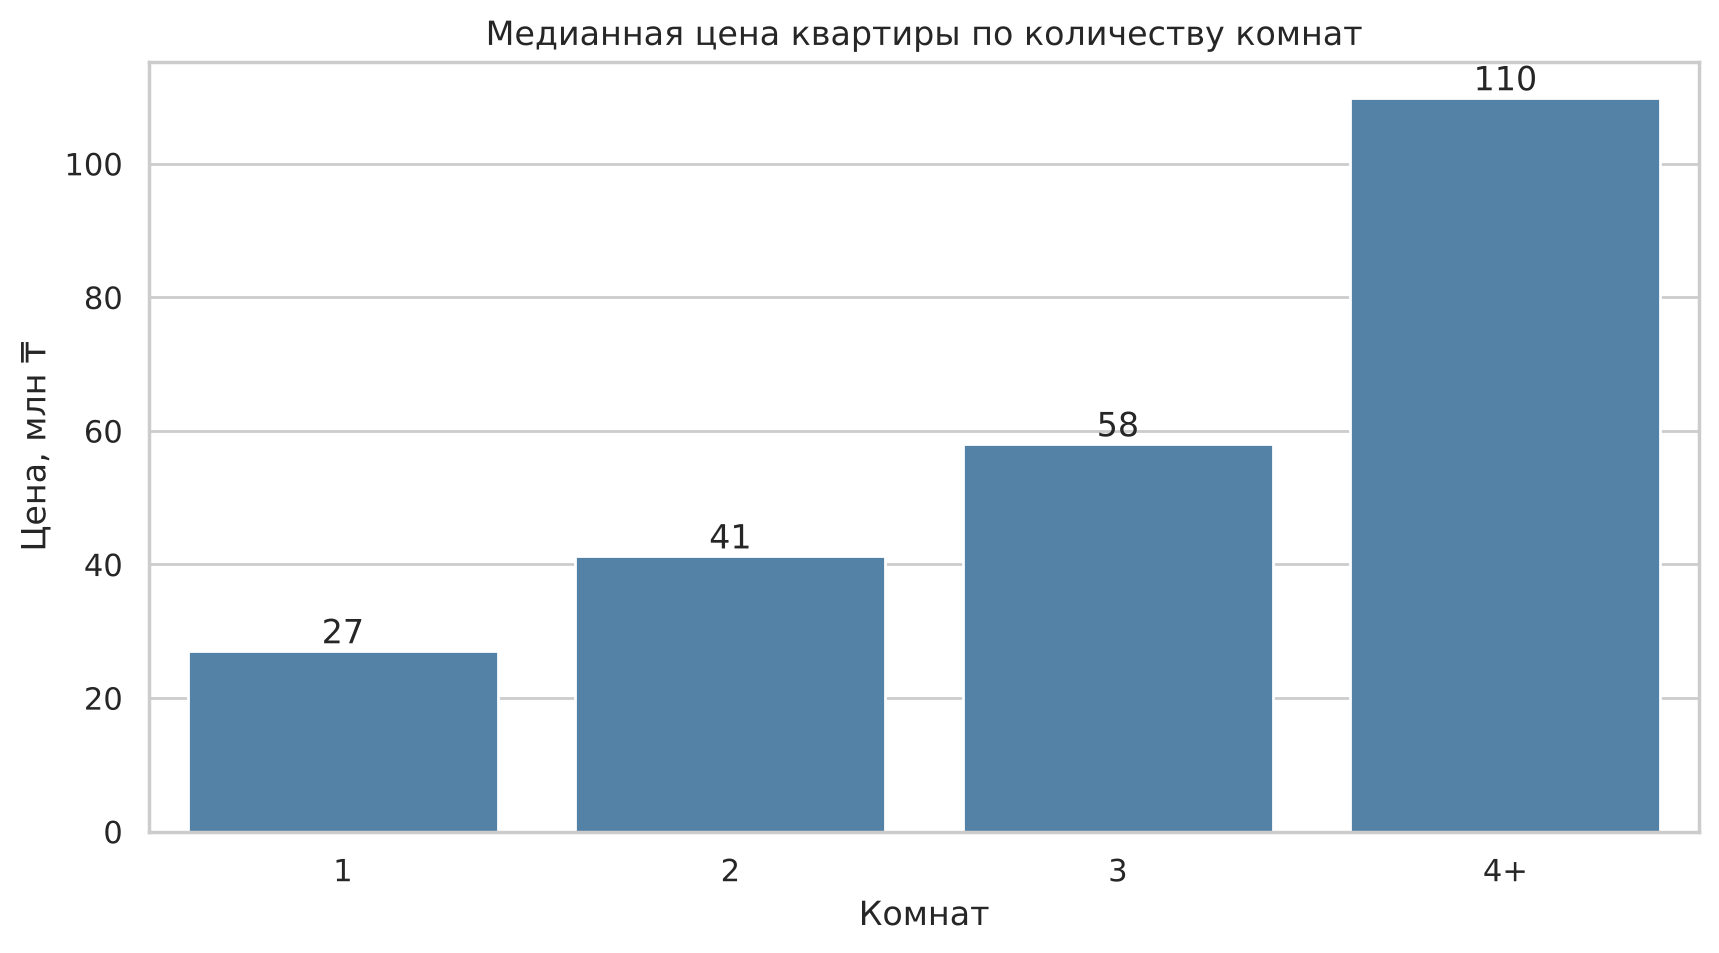

In [10]:
ax = sns.barplot(data=rooms_summary.reset_index(), x='rooms_group', y='median_price_mln', color='steelblue')
ax.bar_label(ax.containers[0], fmt='%.0f')
ax.set(title='Медианная цена квартиры по количеству комнат',
       xlabel='Комнат', ylabel='Цена, млн ₸')
plt.savefig('images/01_price_by_rooms.png', dpi=120, bbox_inches='tight')
plt.show()

**Вывод:** медианная квартира в Алматы стоит **40 млн ₸**. Однокомнатная — около 27 млн, двухкомнатная — 41 млн, трёхкомнатная — 58 млн, 4+ комнат — около 110 млн.

Интересно, что **квадратный метр дороже в больших квартирах**: от 716 тыс. ₸ в однокомнатных до 892 тыс. ₸ в 4+. Обычно бывает наоборот. Скорее всего, большие квартиры чаще продаются в дорогих районах и элитных домах.

### Вопрос 2. Что сильнее всего влияет на цену?

In [11]:
# Корреляция: от -1 до 1. Чем ближе к 1, тем сильнее параметр связан с ценой
corr = df[['price', 'area', 'rooms', 'floor', 'max_floor', 'year_built']].corr()['price']
corr = corr.drop('price').sort_values(ascending=False).round(2)
corr

area          0.84
rooms         0.68
max_floor     0.23
floor         0.14
year_built    0.09
Name: price, dtype: float64

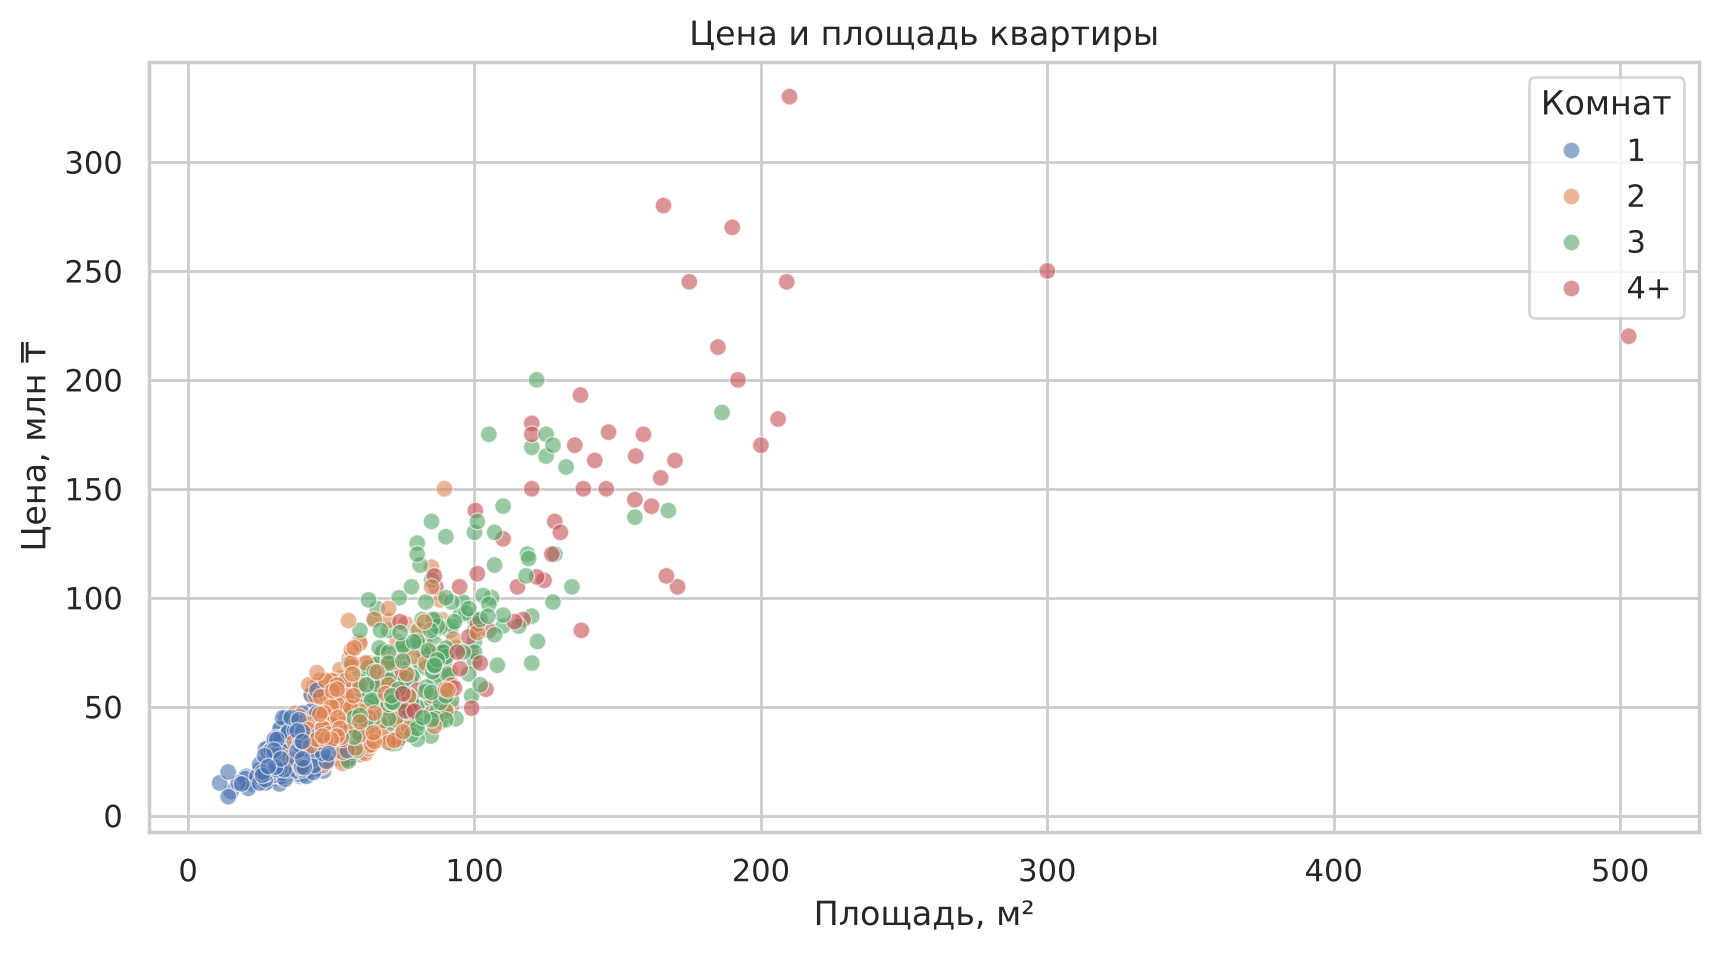

In [12]:
ax = sns.scatterplot(data=df, x='area', y='price_mln', hue='rooms_group',
                     hue_order=['1', '2', '3', '4+'], alpha=0.6)
ax.set(title='Цена и площадь квартиры', xlabel='Площадь, м²', ylabel='Цена, млн ₸')
ax.legend(title='Комнат')
plt.savefig('images/02_price_vs_area.png', dpi=120, bbox_inches='tight')
plt.show()

**Вывод:** сильнее всего на цену влияет **площадь** (корреляция 0,84): точки на графике выстраиваются почти в линию. Количество комнат тоже важно (0,68), но в основном потому, что больше комнат — больше площадь.

Этаж и год постройки с ценой почти не связаны (0,14 и 0,09). Значит, цена квартиры — это в первую очередь её размер, а дальше решает то, чего в наших данных нет: **район**, состояние ремонта, класс дома.

### Вопрос 3. Новостройки дороже старых домов?

In [13]:
building_order = ['до 1991 (советские)', '1991–2010', '2011–2022', '2023+ (новостройки)']

building_summary = df.groupby('building').agg(
    listings=('price', 'count'),
    median_price_m2_k=('price_m2_k', 'median'),
).reindex(building_order).round(0)
building_summary

,listings,median_price_m2_k
building,,
до 1991 (советские),282,790.0
1991–2010,106,728.0
2011–2022,330,714.0
2023+ (новостройки),456,778.0


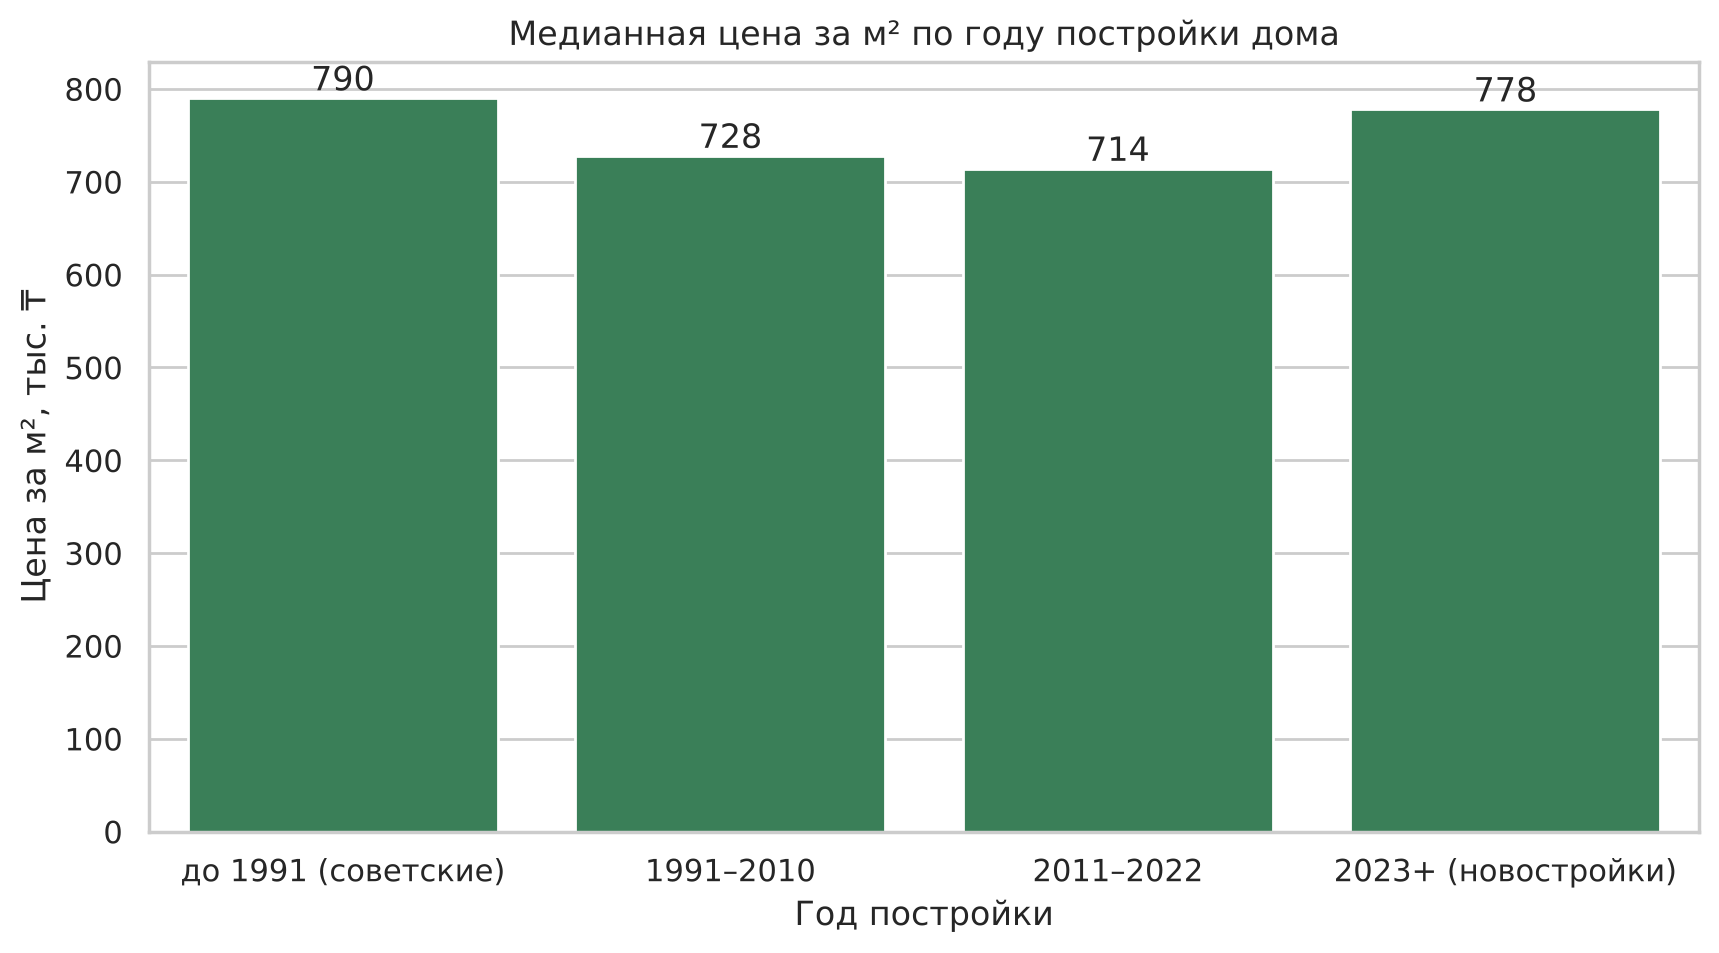

In [14]:
ax = sns.barplot(data=building_summary.reset_index(), x='building', y='median_price_m2_k', color='seagreen')
ax.bar_label(ax.containers[0], fmt='%.0f')
ax.set(title='Медианная цена за м² по году постройки дома',
       xlabel='Год постройки', ylabel='Цена за м², тыс. ₸')
plt.savefig('images/03_price_m2_by_building.png', dpi=120, bbox_inches='tight')
plt.show()

**Вывод:** неожиданно, но **квартиры в советских домах не дешевле новостроек**: 790 тыс. ₸ за м² против 778 тыс. ₸. Дешевле всего дома 2011–2022 годов (714 тыс. ₸).

Вероятное объяснение — расположение. Советские дома стоят в центре города, а многие новостройки строят на окраинах. То есть место влияет на цену сильнее, чем возраст дома. Проверить это можно, если добавить в данные район.

### Вопрос 4. Правда ли, что первый и последний этаж дешевле?

In [15]:
# Убираем одноэтажные дома и квартиры с этажом 0 (ошибка в данных)
df_floors = df[(df['floor'] > 0) & (df['max_floor'] > 1)]

floor_summary = df_floors.groupby('floor_type').agg(
    listings=('price', 'count'),
    median_price_m2_k=('price_m2_k', 'median'),
).reindex(['Первый', 'Средний', 'Последний']).round(0)
floor_summary

,listings,median_price_m2_k
floor_type,,
Первый,133,743.0
Средний,838,774.0
Последний,202,728.0


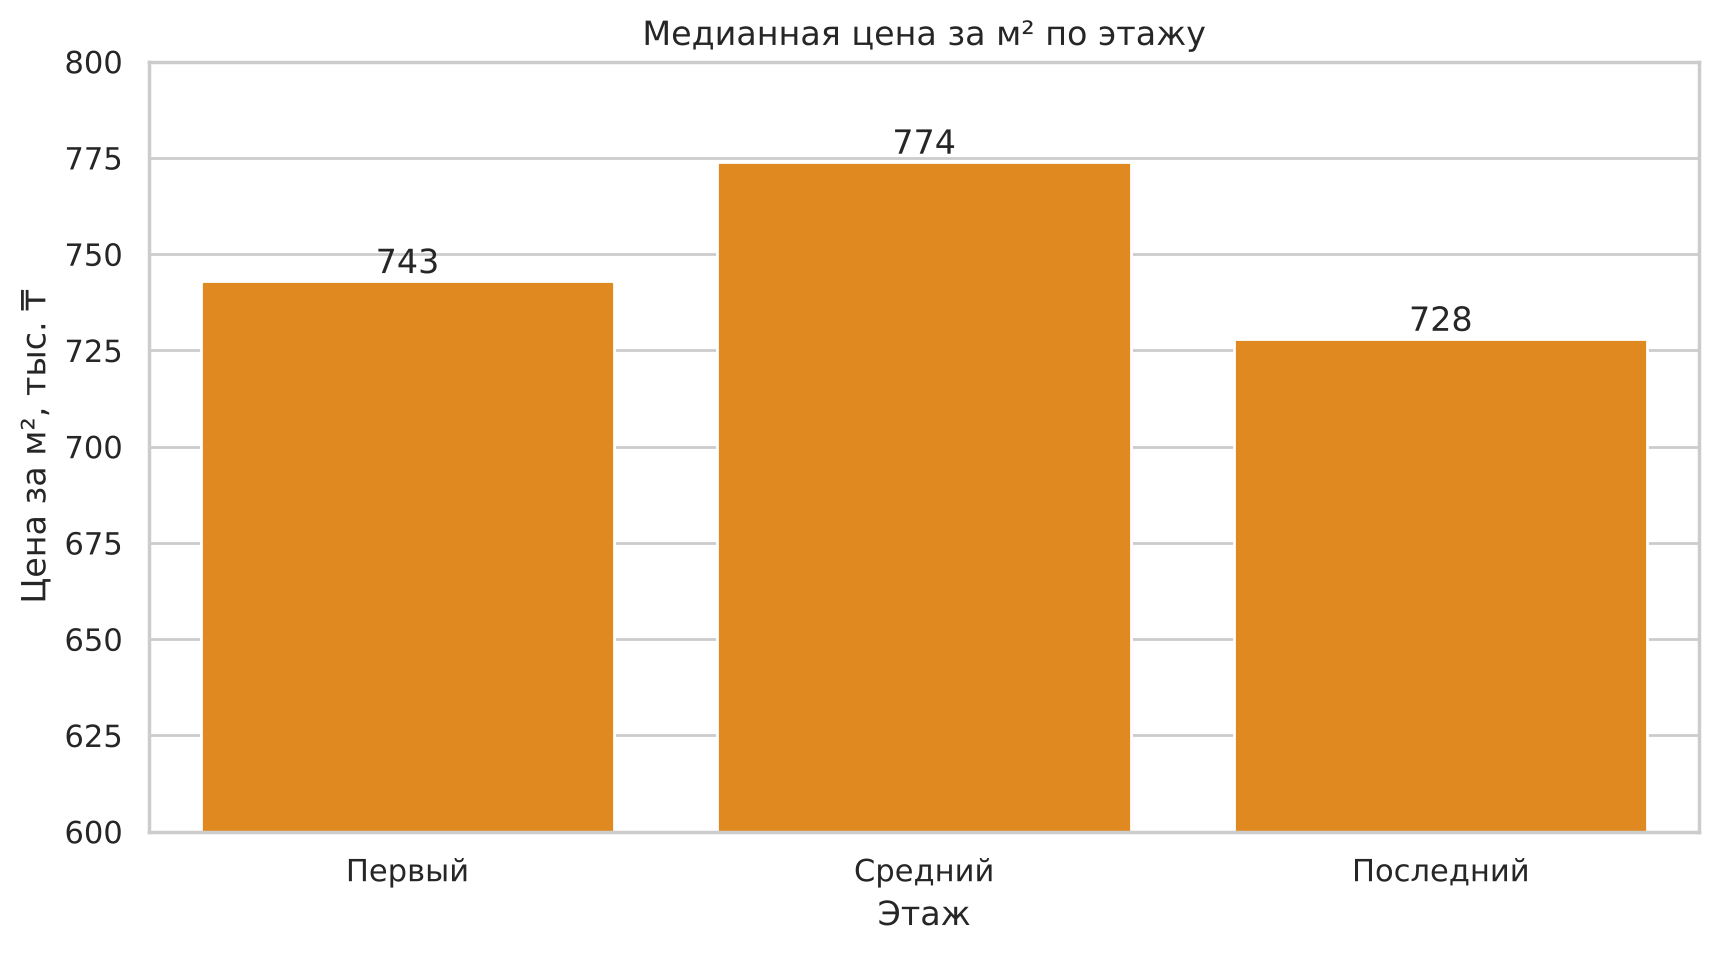

In [16]:
ax = sns.barplot(data=floor_summary.reset_index(), x='floor_type', y='median_price_m2_k', color='darkorange')
ax.bar_label(ax.containers[0], fmt='%.0f')
ax.set(title='Медианная цена за м² по этажу', xlabel='Этаж', ylabel='Цена за м², тыс. ₸')
ax.set_ylim(600, 800)
plt.savefig('images/04_price_m2_by_floor.png', dpi=120, bbox_inches='tight')
plt.show()

**Вывод:** да, но не сильно. Квадратный метр на **первом этаже дешевле на 4%**, на **последнем — на 6%**, чем на средних этажах. Покупатели готовы немного доплатить, чтобы не жить на первом (шум, безопасность) и последнем (крыша, жара летом).

Ось Y на графике начинается с 600, чтобы разница была видна. На собеседовании об этом стоит сказать: иначе график преувеличивает разницу.

### Вопрос 5. Какие квартиры чаще всего продаются?

In [17]:
rooms_share = (df['rooms_group'].value_counts(normalize=True) * 100).sort_index().round(1)
new_share = (df['building'] == '2023+ (новостройки)').mean() * 100

print('Доля объявлений по комнатам, %:')
print(rooms_share)
print(f'\nДоля новостроек (2023+): {new_share:.0f}%')

Доля объявлений по комнатам, %:
rooms_group
1     31.3
2     38.0
3     25.0
4+     5.8
Name: proportion, dtype: float64

Доля новостроек (2023+): 39%


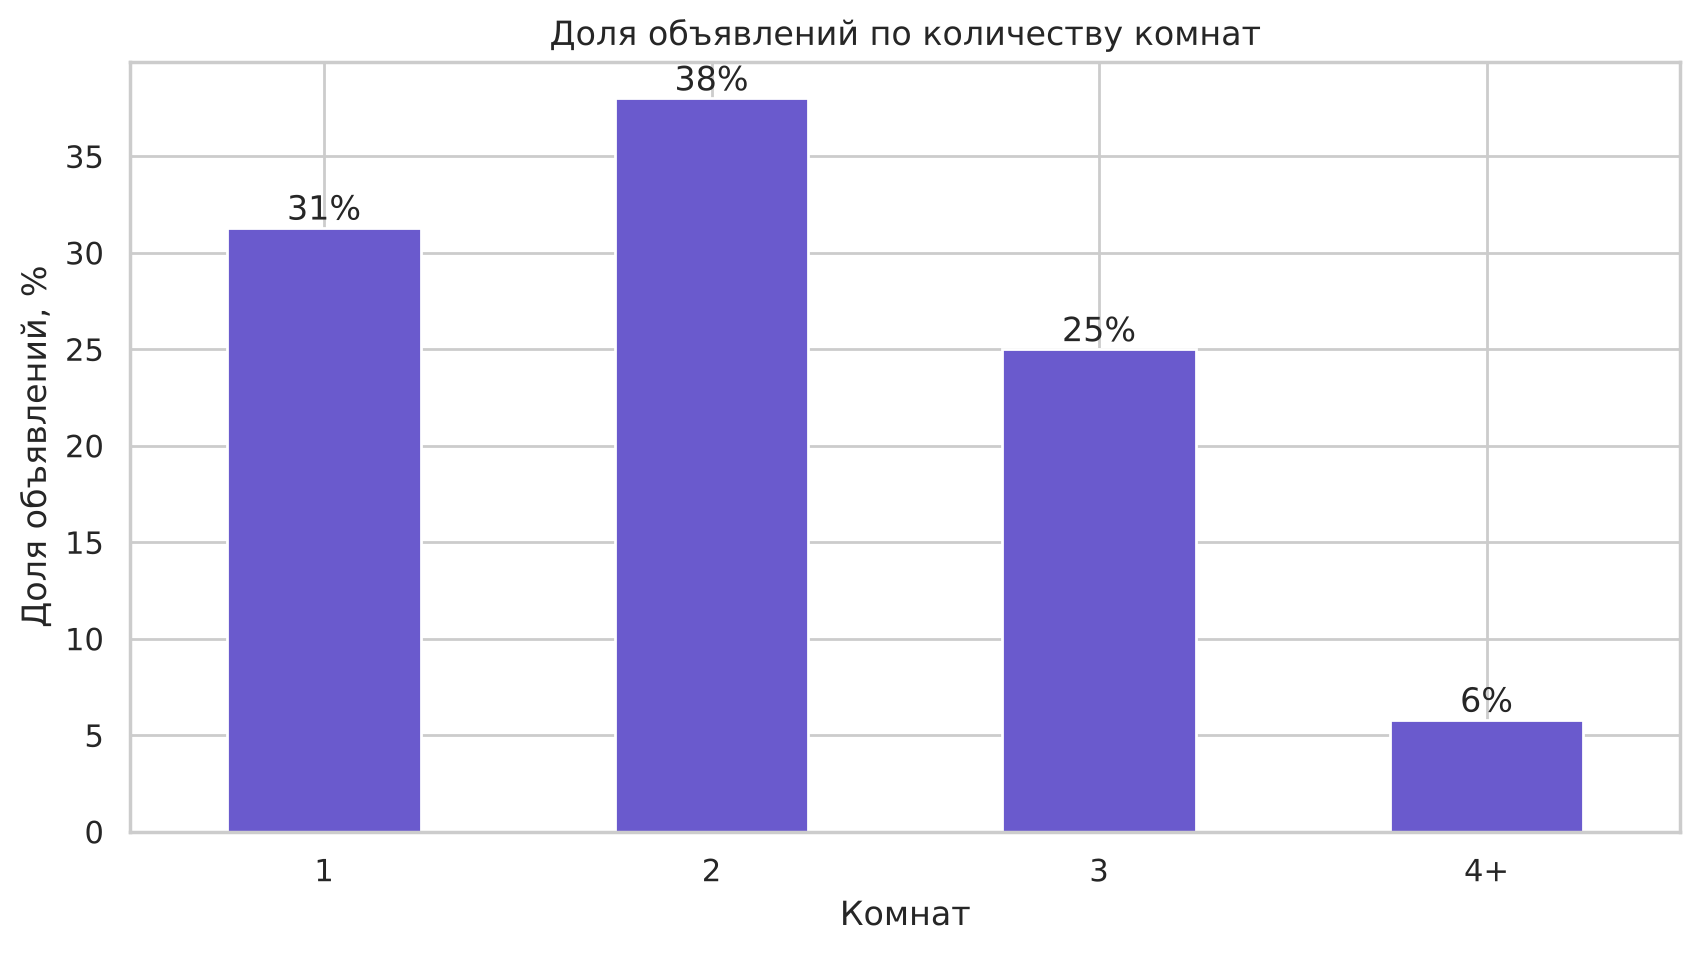

In [18]:
ax = rooms_share.plot(kind='bar', color='slateblue', rot=0)
ax.bar_label(ax.containers[0], fmt='%.0f%%')
ax.set(title='Доля объявлений по количеству комнат', xlabel='Комнат', ylabel='Доля объявлений, %')
plt.savefig('images/05_listings_by_rooms.png', dpi=120, bbox_inches='tight')
plt.show()

**Вывод:** рынок — это в основном небольшие квартиры: **1- и 2-комнатные дают 69%** всех объявлений, самые частые — двухкомнатные (38%). Квартир на 4 и больше комнат всего 6%.

**39%** объявлений — новостройки 2023 года и новее, включая дома, которые ещё строятся (год постройки 2026–2027). Рынок Алматы сильно держится на новом строительстве.

## 5. Бонус: модель для оценки цены квартиры

Попробуем предсказать цену квартиры по её параметрам: площадь, комнаты, этаж, этажность дома, год постройки.

Чтобы понять, хороша ли модель, сравним её с **простым ориентиром**: «площадь × медианная цена за м²». Так цену прикидывает любой человек с калькулятором. Если модель не лучше калькулятора, она не нужна.

**Как оцениваем:** средняя ошибка в млн ₸ (MAE) и в процентах от цены (MAPE).

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

features = ['area', 'rooms', 'floor', 'max_floor', 'year_built']
X = df[features]
y = df['price_mln']

# 80% данных — для обучения, 20% — для проверки на квартирах, которых модель не видела
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Обучение:', len(X_train), '| проверка:', len(X_test))

Обучение: 939 | проверка: 235


In [20]:
# Простой ориентир: площадь × медианная цена м² (считаем по обучающим данным)
median_m2 = (y_train / X_train['area']).median()
baseline_pred = X_test['area'] * median_m2

# Линейная регрессия: ищет «прямую линию» зависимости цены от параметров
lr = LinearRegression().fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# Случайный лес: много деревьев решений, каждое делает прогноз, результат усредняется
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42).fit(X_train, y_train)
rf_pred = rf.predict(X_test)

results = pd.DataFrame({
    'Модель': ['Ориентир: площадь × цена м²', 'Линейная регрессия', 'Случайный лес'],
    'Ошибка, млн ₸': [mean_absolute_error(y_test, p) for p in [baseline_pred, lr_pred, rf_pred]],
    'Ошибка, %': [mean_absolute_percentage_error(y_test, p) * 100 for p in [baseline_pred, lr_pred, rf_pred]],
}).round(1)
results

,Модель,"Ошибка, млн ₸","Ошибка, %"
0,Ориентир: площадь × цена м²,12.0,23.0
1,Линейная регрессия,11.9,24.8
2,Случайный лес,10.3,20.7


In [21]:
# Пример: 2-комнатная, 60 м², 5 этаж из 10, дом 2020 года
my_flat = pd.DataFrame([{'area': 60, 'rooms': 2, 'floor': 5, 'max_floor': 10, 'year_built': 2020}])
print(f'Оценка случайного леса: {rf.predict(my_flat)[0]:.0f} млн ₸')
print(f'Оценка по ориентиру:    {60 * median_m2:.0f} млн ₸')

Оценка случайного леса: 44 млн ₸
Оценка по ориентиру:    46 млн ₸


**Вывод:** случайный лес ошибается в среднем на **21%** от цены, а простой расчёт «площадь × цена м²» — на **23%**. Линейная регрессия вообще не лучше калькулятора.

Модель почти не выигрывает у простой формулы, потому что в данных нет главного для цены: **района**, ремонта и класса дома. Это честный и полезный результат: чтобы улучшить оценку, нужно не усложнять модель, а **собирать больше информации о квартире**.

## 6. Итоги

1. **Медианная квартира в Алматы стоит 40 млн ₸**, медианная цена — 764 тыс. ₸ за м² (снимок рынка, ноябрь 2025).
2. **Главный фактор цены — площадь** (корреляция 0,84). Этаж и год постройки на цену почти не влияют.
3. **Советские дома не дешевле новостроек** за м². Вероятно, решает расположение: старые дома в центре, новые часто на окраинах.
4. **Первый и последний этажи дешевле** средних на 4–6% за м².
5. **Рынок — это 1–2-комнатные квартиры** (69% объявлений), а 39% предложения — новостройки.
6. **Модель оценки цены** ошибается на ~21%, почти как простой расчёт по площади. Без данных о районе точнее оценить нельзя.

**Ограничения:** одна площадка объявлений, снимок за один момент времени, цены — это цены в объявлениях, а не реальных сделок, в данных нет района.

**Что можно улучшить:** собирать район и состояние квартиры, повторять сбор раз в месяц, чтобы видеть динамику цен.